# Tour-Level K-Means Clustering Comparison

## Vehicle Telemetry Analysis for Improving Efficiency in Logistics Fleet Operations

### 1. Objective

The objective of this experiment is to compare K-Means clustering on two representations of the same tour-level vehicle telemetry dataset:

1. **Standardized feature space:** Five standardized operational features generated during the tour-level PCA workflow.
2. **Reduced PCA space:** The first two principal component scores, retaining 91.081% of the variance in the five standardized features.

The experiment will investigate whether dimensionality reduction changes cluster separation, cluster-size distribution, stability, and operational interpretability.

### 2. Research Questions

- How does clustering in the five-dimensional standardized feature space compare with clustering in the two-dimensional PCA space?
- What silhouette scores are obtained for different values of \(k\)?
- Are the resulting clusters reasonably populated, or do some solutions produce very small clusters?
- How consistent are cluster assignments across repeated K-Means initializations?
- Do the clusters differ meaningfully in operational characteristics such as distance, recorded duration, elapsed span, average speed, and track count?

### 3. Evaluation Criteria

The comparison will consider:

- Silhouette score
- Cluster-size distribution
- Stability across random initializations
- Operational profiles of the resulting clusters

Silhouette scores will be interpreted within each feature representation because distances and geometries differ between the original standardized feature space and the reduced PCA space.

### 4. Data and Reproducibility

The experiment uses the previously generated tour-level PCA outputs. The original telemetry data and completed PCA notebook will remain unchanged.

Both representations must contain the same eligible tours in the same verified identifier order before clustering results are compared.

### 5. Interpretation and Limitations

K-Means produces exploratory groups based on feature-space distances. These groups must not automatically be interpreted as verified trip types, driving behaviors, or measures of operational efficiency.

Cluster interpretations will be based on observed feature profiles and data-quality limitations. Results will be documented without assuming that either representation is superior before evaluation.

In [2]:
from pathlib import Path
import json

import numpy as np
import pandas as pd

# Resolve project root
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

OUTPUT_DIR = PROJECT_ROOT / "data" / "processed" / "tour_level_pca"

standardized_path = OUTPUT_DIR / "tour_level_pca_standardized_features.csv"
scores_path = OUTPUT_DIR / "tour_level_pca_reduced_scores.csv"
metadata_path = OUTPUT_DIR / "tour_level_pca_metadata.json"

# Verify required files
for path in [standardized_path, scores_path, metadata_path]:
    print(f"{path.name}: exists = {path.exists()}")

if not all(path.exists() for path in [
    standardized_path,
    scores_path,
    metadata_path
]):
    raise FileNotFoundError(
        "Required PCA outputs are missing. "
        "Verify the project root and output directory."
    )

# Load saved outputs
X_standardized = pd.read_csv(standardized_path)
pca_scores = pd.read_csv(scores_path)

with open(metadata_path, "r", encoding="utf-8") as file:
    pca_metadata = json.load(file)

print("\nProject root:", PROJECT_ROOT)
print("Standardized feature shape:", X_standardized.shape)
print("PCA score shape:", pca_scores.shape)

print("\nStandardized feature columns:")
print(X_standardized.columns.tolist())

print("\nPCA score columns:")
print(pca_scores.columns.tolist())

print("\nMissing values in standardized features:",
      int(X_standardized.isna().sum().sum()))

print("Missing values in PCA scores:",
      int(pca_scores.isna().sum().sum()))

print("\nPCA metadata:")
print(json.dumps(pca_metadata, indent=2))

display(X_standardized.head())
display(pca_scores.head())

tour_level_pca_standardized_features.csv: exists = True
tour_level_pca_reduced_scores.csv: exists = True
tour_level_pca_metadata.json: exists = True

Project root: /Users/divyshah/Downloads/dt-cargo-vehicle-telemetry--main
Standardized feature shape: (13413, 7)
PCA score shape: (13413, 4)

Standardized feature columns:
['vehicle_id', 'tour_id', 'scaled_total_distance_km', 'scaled_recorded_track_hours', 'scaled_elapsed_span_hours', 'scaled_distance_based_avg_speed_kmh', 'scaled_track_count']

PCA score columns:
['vehicle_id', 'tour_id', 'PCPC1', 'PCPC2']

Missing values in standardized features: 0
Missing values in PCA scores: 0

PCA metadata:
{
  "analysis_unit": "candidate tour identified by (vehicle_id, tour_id)",
  "input_file": "data/processed/tour_level/retained_tours_quality_checked.csv",
  "candidate_features": [
    "total_distance_km",
    "recorded_track_hours",
    "elapsed_span_hours",
    "distance_based_avg_speed_kmh",
    "track_count"
  ],
  "log1p_features": [
    "tot

,vehicle_id,tour_id,scaled_total_distance_km,scaled_recorded_track_hours,scaled_elapsed_span_hours,scaled_distance_based_avg_speed_kmh,scaled_track_count
0,1,0,0.481607,0.093566,-0.319792,0.164781,-0.472546
1,1,1,-1.226300,-0.989503,1.768750,-0.948343,0.317756
2,1,2,0.276887,-0.227786,1.179232,0.142068,0.452048
3,1,3,-0.439316,0.878748,3.344490,-0.964982,3.253129
4,1,4,1.883591,2.379779,1.500796,1.621898,1.177179


,vehicle_id,tour_id,PCPC1,PCPC2
0,1,0,0.010259,0.679849
1,1,1,-0.570288,-2.037832
2,1,2,0.760905,-0.594120
3,1,3,2.673409,-3.989283
4,1,4,3.887184,0.424847


## 2. Experimental Design

### 2.1 Feature Representations

Two feature representations will be compared:

**Representation A — Standardized feature space**

Five features will be used:

- `scaled_total_distance_km`
- `scaled_recorded_track_hours`
- `scaled_elapsed_span_hours`
- `scaled_distance_based_avg_speed_kmh`
- `scaled_track_count`

**Representation B — Reduced PCA space**

Two principal component scores will be used:

- `PC1`
- `PC2`

The saved PCA metadata reports that these components retain 91.081% of the variance in the five-feature input space.

### 2.2 Identifier Handling

The identifiers `vehicle_id` and `tour_id` will be retained for row alignment and result interpretation. They will not be included as K-Means input features.

Both representations will be aligned using the composite key `(vehicle_id, tour_id)`. Duplicate keys, mismatched tours, missing values, and non-numeric feature values will be checked before clustering.

### 2.3 Clustering and Evaluation

K-Means will be evaluated over a documented range of cluster counts. The comparison will consider silhouette scores, cluster sizes, stability across random initializations, and operational profiles.

Because the two representations have different dimensionalities, their silhouette scores will be interpreted within the geometry of each representation. A higher score alone will not establish that a clustering solution is more operationally useful.

In [3]:

# Identifier columns used only for alignment
KEYS = ["vehicle_id", "tour_id"]

# Rename PCA columns in memory for readability
pca_scores = pca_scores.rename(
    columns={"PCPC1": "PC1", "PCPC2": "PC2"}
)

# Validate required columns
standardized_features = [
    "scaled_total_distance_km",
    "scaled_recorded_track_hours",
    "scaled_elapsed_span_hours",
    "scaled_distance_based_avg_speed_kmh",
    "scaled_track_count",
]

pca_features = ["PC1", "PC2"]

for col in KEYS + standardized_features:
    if col not in X_standardized.columns:
        raise ValueError(f"Missing column in standardized data: {col}")

for col in KEYS + pca_features:
    if col not in pca_scores.columns:
        raise ValueError(f"Missing column in PCA scores: {col}")

# Check identifier validity and uniqueness
for name, frame in [
    ("Standardized", X_standardized),
    ("PCA scores", pca_scores),
]:
    if frame[KEYS].isna().any().any():
        raise ValueError(f"{name} data contains missing tour identifiers.")

    if frame.duplicated(KEYS).any():
        raise ValueError(f"{name} data contains duplicate tour keys.")

# Align both datasets by composite key
standardized_aligned = (
    X_standardized[KEYS + standardized_features]
    .set_index(KEYS)
    .sort_index()
)

pca_aligned = (
    pca_scores[KEYS + pca_features]
    .set_index(KEYS)
    .sort_index()
)

if not standardized_aligned.index.equals(pca_aligned.index):
    raise ValueError(
        "Tour keys differ between standardized features and PCA scores."
    )

# Numeric feature matrices; IDs are excluded
X_full = standardized_aligned[standardized_features].astype(float)
X_pca = pca_aligned[pca_features].astype(float)

if not np.isfinite(X_full.to_numpy()).all():
    raise ValueError("Standardized feature matrix has non-finite values.")

if not np.isfinite(X_pca.to_numpy()).all():
    raise ValueError("PCA score matrix has non-finite values.")

print("Tour keys aligned:", X_full.index.equals(X_pca.index))
print("Same eligible tours:", len(X_full) == len(X_pca))
print("Tour count:", len(X_full))
print("Full feature matrix shape:", X_full.shape)
print("PCA feature matrix shape:", X_pca.shape)
print("Full matrix finite:", np.isfinite(X_full.to_numpy()).all())
print("PCA matrix finite:", np.isfinite(X_pca.to_numpy()).all())

display(X_full.head())
display(X_pca.head())


Tour keys aligned: True
Same eligible tours: True
Tour count: 13413
Full feature matrix shape: (13413, 5)
PCA feature matrix shape: (13413, 2)
Full matrix finite: True
PCA matrix finite: True


scaled_total_distance_km  scaled_recorded_track_hours  \
vehicle_id tour_id                                                          
1          0                        0.481607                     0.093566   
           1                       -1.226300                    -0.989503   
           2                        0.276887                    -0.227786   
           3                       -0.439316                     0.878748   
           4                        1.883591                     2.379779   

                    scaled_elapsed_span_hours  \
vehicle_id tour_id                              
1          0                        -0.319792   
           1                         1.768750   
           2                         1.179232   
           3                         3.344490   
           4                         1.500796   

                    scaled_distance_based_avg_speed_kmh  scaled_track_count  
vehicle_id tour_id                                                           
1          0                                   0.164781           -0.472546  
           1                                  -0.948343            0.317756  
           2                                   0.142068            0.452048  
           3                                  -0.964982            3.253129  
           4                                   1.621898            1.177179

PC1       PC2
vehicle_id tour_id                    
1          0        0.010259  0.679849
           1       -0.570288 -2.037832
           2        0.760905 -0.594120
           3        2.673409 -3.989283
           4        3.887184  0.424847

## 3. K-Means Clustering Methodology

### 3.1 Algorithm

K-Means partitions observations into \(k\) clusters by assigning each observation to its nearest centroid and iteratively updating the centroids to reduce within-cluster squared distances.

The algorithm will be applied independently to:

- The five-dimensional standardized operational feature matrix.
- The two-dimensional PCA score matrix.

### 3.2 Candidate Cluster Counts

Candidate values of \(k\) will be evaluated over a predefined range. Silhouette scores and cluster sizes will be used to identify promising solutions, rather than selecting a cluster count solely because it produces the highest score.

### 3.3 Reproducibility

A fixed random seed and multiple K-Means initializations will be used to reduce sensitivity to random centroid initialization. Stability will also be evaluated across repeated seeds.

### 3.4 Evaluation Caution

Silhouette scores measure cohesion and separation under a chosen distance metric. Because the original feature space and PCA space have different geometries, their scores are not perfectly interchangeable.

The final solution will be evaluated using both quantitative metrics and operational profiles. No cluster will be assigned a business meaning until its feature characteristics have been examined.

In [4]:

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

K_VALUES = range(2, 9)
RANDOM_STATE = 42
N_INIT = 20
SILHOUETTE_SAMPLE_SIZE = min(3000, len(X_full))

# Use the same observations for silhouette evaluation in both spaces
rng = np.random.default_rng(RANDOM_STATE)
sample_positions = np.sort(
    rng.choice(
        len(X_full),
        size=SILHOUETTE_SAMPLE_SIZE,
        replace=False,
    )
)

X_full_array = X_full.to_numpy()
X_pca_array = X_pca.to_numpy()

results = []
labels_by_representation = {}

for representation, X in [
    ("standardized_5d", X_full_array),
    ("pca_2d", X_pca_array),
]:
    print(f"Evaluating {representation}...")

    for k in K_VALUES:
        model = KMeans(
            n_clusters=k,
            random_state=RANDOM_STATE,
            n_init=N_INIT,
        )

        labels = model.fit_predict(X)
        labels_by_representation[(representation, k)] = labels

        sample_labels = labels[sample_positions]
        sample_X = X[sample_positions]

        if len(np.unique(sample_labels)) < 2:
            silhouette = np.nan
        else:
            silhouette = silhouette_score(
                sample_X,
                sample_labels,
                metric="euclidean",
            )

        counts = np.bincount(labels, minlength=k)

        results.append({
            "representation": representation,
            "k": k,
            "silhouette_sampled": silhouette,
            "inertia": model.inertia_,
            "smallest_cluster": int(counts.min()),
            "largest_cluster": int(counts.max()),
            "smallest_cluster_pct": float(counts.min() / len(labels) * 100),
            "largest_cluster_pct": float(counts.max() / len(labels) * 100),
            "cluster_sizes": counts.tolist(),
        })

k_results = pd.DataFrame(results)

display(
    k_results[
        [
            "representation",
            "k",
            "silhouette_sampled",
            "inertia",
            "smallest_cluster",
            "largest_cluster",
            "smallest_cluster_pct",
            "largest_cluster_pct",
            "cluster_sizes",
        ]
    ].round(4)
)


Evaluating standardized_5d...
Evaluating pca_2d...


,representation,k,silhouette_sampled,inertia,smallest_cluster,largest_cluster,smallest_cluster_pct,largest_cluster_pct,cluster_sizes
0,standardized_5d,2,0.4235,36980.7692,6542,6871,48.7736,51.2264,"[6542, 6871]"
1,standardized_5d,3,0.4382,26721.7200,1638,6284,12.2120,46.8501,"[6284, 5491, 1638]"
2,standardized_5d,4,0.4525,20336.5521,1157,5478,8.6260,40.8410,"[2033, 5478, 1157, 4745]"
3,standardized_5d,5,0.3948,16990.0533,981,4114,7.3138,30.6717,"[4114, 3376, 981, 1977, 2965]"
4,standardized_5d,6,0.4036,14484.4867,672,3870,5.0101,28.8526,"[2983, 3323, 672, 759, 3870, 1806]"
5,standardized_5d,7,0.3983,13050.9426,578,3770,4.3093,28.1071,"[1604, 3770, 1796, 752, 578, 2027, 2886]"
6,standardized_5d,8,0.3988,11863.6792,4,3762,0.0298,28.0474,"[2075, 3762, 1796, 1580, 2869, 750, 577, 4]"
7,pca_2d,2,0.4619,31015.8898,6540,6873,48.7587,51.2413,"[6873, 6540]"
8,pca_2d,3,0.4838,20818.6705,1649,6301,12.2940,46.9768,"[5463, 6301, 1649]"
9,pca_2d,4,0.4983,14903.8653,1100,5390,8.2010,40.1849,"[5390, 2011, 1100, 4912]"


## 4. Preliminary Model Selection

### 4.1 Silhouette Results

Across the tested range \(k=2,\ldots,8\), the PCA representation produced a higher sampled silhouette score than the five-dimensional standardized representation for every tested cluster count.

The highest sampled silhouette score for both representations occurred at \(k=4\):

- Standardized feature space: 0.4525
- PCA space: 0.4983

### 4.2 Cluster-Size Assessment

At \(k=4\), all clusters contain a meaningful number of candidate tours in both representations. At \(k=8\), the standardized feature solution contains a cluster of only four tours, suggesting a potentially undesirable partition.

### 4.3 Provisional Decision

Four clusters will be carried forward as a candidate solution for stability and operational-profile analysis.

This choice is provisional. The final cluster count will be assessed using repeated initializations, cluster-size diagnostics, and the operational characteristics of each cluster. Silhouette scores alone are not sufficient to establish business usefulness.

In [5]:

from sklearn.metrics import adjusted_rand_score

K_SELECTED = 4
STABILITY_SEEDS = [7, 21, 42, 84, 123, 202, 314, 512, 777, 1001]

stability_records = {}
stability_rows = []

for representation, X in [
    ("standardized_5d", X_full_array),
    ("pca_2d", X_pca_array),
]:
    reference_labels = KMeans(
        n_clusters=K_SELECTED,
        random_state=42,
        n_init=20,
    ).fit_predict(X)

    seed_labels = {}

    for seed in STABILITY_SEEDS:
        labels = KMeans(
            n_clusters=K_SELECTED,
            random_state=seed,
            n_init=20,
        ).fit_predict(X)

        seed_labels[seed] = labels
        stability_rows.append({
            "representation": representation,
            "seed": seed,
            "ARI_vs_reference_seed_42": adjusted_rand_score(
                reference_labels, labels
            ),
        })

    stability_records[representation] = seed_labels

stability_df = pd.DataFrame(stability_rows)

display(stability_df.round(4))

stability_summary = (
    stability_df.groupby("representation")["ARI_vs_reference_seed_42"]
    .agg(["mean", "std", "min", "max"])
    .reset_index()
)

print("\nStability summary:")
display(stability_summary.round(4))


,representation,seed,ARI_vs_reference_seed_42
0,standardized_5d,7,0.9984
1,standardized_5d,21,0.9998
2,standardized_5d,42,1.0000
3,standardized_5d,84,0.9987
4,standardized_5d,123,0.9984
5,standardized_5d,202,0.9991
6,standardized_5d,314,0.9984
7,standardized_5d,512,0.9984
8,standardized_5d,777,0.9984
9,standardized_5d,1001,0.9998



Stability summary:


,representation,mean,std,min,max
0,pca_2d,0.9986,0.0010,0.9974,1.0
1,standardized_5d,0.9989,0.0007,0.9984,1.0


## 5. K-Means Stability Assessment

The four-cluster K-Means solutions were evaluated across ten random seeds, with 20 initializations per fit.

The mean Adjusted Rand Index (ARI) relative to the reference solution was:

- Standardized feature space: 0.9989
- PCA space: 0.9986

Both representations produced highly consistent cluster assignments across the tested random seeds. The small difference between the mean ARI values does not provide strong evidence that one representation is more stable than the other.

This experiment measures sensitivity to initialization on the same dataset. It does not establish stability under data resampling, distribution shifts, or changes in feature engineering.

The \(k=4\) solutions will therefore be carried forward to operational profiling, with no final preference assigned solely on the basis of stability.

In [6]:

from sklearn.cluster import KMeans

# Load the original tour-level table for operational interpretation
tour_data_path = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "tour_level"
    / "retained_tours_quality_checked.csv"
)

tour_data = pd.read_csv(tour_data_path)

KEYS = ["vehicle_id", "tour_id"]

# Verify that the original data contains unique tour keys
if tour_data[KEYS].isna().any().any():
    raise ValueError("Original tour data contains missing identifiers.")

if tour_data.duplicated(KEYS).any():
    raise ValueError("Original tour data contains duplicate tour keys.")

# Align operational data to the PCA experiment's exact tour order
operational = (
    tour_data
    .set_index(KEYS)
    .reindex(X_full.index)
)

if operational.index.has_duplicates or operational.isna().all(axis=1).any():
    raise ValueError("Could not align original tour data to clustering rows.")

# Fit final candidate models with the reference seed
model_full_k4 = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=20,
)
labels_full_k4 = model_full_k4.fit_predict(X_full_array)

model_pca_k4 = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=20,
)
labels_pca_k4 = model_pca_k4.fit_predict(X_pca_array)

# Build a tour-level result table
cluster_results = pd.DataFrame(
    index=X_full.index
).reset_index()

cluster_results["cluster_standardized"] = labels_full_k4
cluster_results["cluster_pca"] = labels_pca_k4

# Add original operational measurements
profile_columns = [
    "total_distance_km",
    "recorded_track_hours",
    "elapsed_span_hours",
    "distance_based_avg_speed_kmh",
    "track_count",
]

for col in profile_columns:
    if col not in operational.columns:
        raise ValueError(f"Missing operational profile column: {col}")

operational_reset = operational.reset_index()[KEYS + profile_columns]

cluster_results = cluster_results.merge(
    operational_reset,
    on=KEYS,
    how="left",
    validate="one_to_one",
)

# Profile each clustering solution
for label_col, representation in [
    ("cluster_standardized", "Standardized feature space"),
    ("cluster_pca", "PCA space"),
]:
    print(f"\n{representation}: cluster sizes")
    display(
        cluster_results[label_col]
        .value_counts()
        .sort_index()
        .rename("tour_count")
        .to_frame()
    )

    print(f"\n{representation}: operational medians")
    display(
        cluster_results.groupby(label_col)[profile_columns]
        .median()
        .round(3)
    )

    print(f"\n{representation}: operational means")
    display(
        cluster_results.groupby(label_col)[profile_columns]
        .mean()
        .round(3)
    )



Standardized feature space: cluster sizes


,tour_count
cluster_standardized,
0,2033
1,5478
2,1157
3,4745



Standardized feature space: operational medians


,total_distance_km,recorded_track_hours,elapsed_span_hours,distance_based_avg_speed_kmh,track_count
cluster_standardized,,,,,
0,1.712,0.797,16.243,2.209,9.0
1,116.012,3.239,5.070,40.658,5.0
2,707.981,15.751,59.206,46.782,29.0
3,0.922,0.219,0.701,5.081,2.0



Standardized feature space: operational means


...

,tour_count
cluster_pca,
0,5390
1,2011
2,1100
3,4912



PCA space: operational medians


,total_distance_km,recorded_track_hours,elapsed_span_hours,distance_based_avg_speed_kmh,track_count
cluster_pca,,,,,
0,117.560,3.230,5.065,40.828,5.0
1,2.065,0.980,17.133,2.216,10.0
2,739.768,16.067,58.914,48.567,28.0
3,0.908,0.221,0.751,4.965,2.0



PCA space: operational means


,total_distance_km,recorded_track_hours,elapsed_span_hours,distance_based_avg_speed_kmh,track_count
cluster_pca,,,,,
0,163.322,3.666,7.237,42.889,5.426
1,7.936,1.744,47.755,4.584,17.531
2,823.950,20.197,184.193,42.412,53.789
3,4.038,0.372,1.628,7.727,2.377


## 6. Agreement Between Standardized-Space and PCA-Space Clustering

The two K-Means models produce four clusters using the same eligible tours but different feature representations. Because cluster labels are arbitrary, direct label-by-label comparison is not meaningful.

We compare the assignments using the Adjusted Rand Index (ARI) and a contingency table. ARI measures agreement between two partitions: values near 1 indicate strong agreement, values near 0 indicate agreement comparable to chance under the index's reference model.

The contingency table identifies which standardized-space clusters correspond most closely to PCA-space clusters. This helps determine whether PCA preserves individual tour groupings or mainly preserves the broad operational profiles.

In [7]:
from sklearn.metrics import adjusted_rand_score
import pandas as pd

# Confirm both label arrays correspond to the same ordered tour records.
assert len(labels_full_k4) == len(labels_pca_k4) == len(X_full)
assert X_full.index.equals(X_pca.index)

# Compare the two partitions independently of cluster label numbers.
cross_representation_ari = adjusted_rand_score(
    labels_full_k4,
    labels_pca_k4
)

print(
    "Adjusted Rand Index between representations:",
    round(cross_representation_ari, 4)
)

# Rows = standardized-space clusters; columns = PCA-space clusters.
agreement_table = pd.crosstab(
    pd.Series(labels_full_k4, name="Standardized cluster"),
    pd.Series(labels_pca_k4, name="PCA cluster")
)

display(agreement_table)

Adjusted Rand Index between representations: 0.944


PCA cluster,0,1,2,3
Standardized cluster,,,,
0,13,1861,2,157
1,5373,76,14,15
2,4,69,1084,0
3,0,5,0,4740


## 7. Cluster-Level Data-Quality Review

The clustering results are descriptive, and some candidate tours have previously identified quality concerns. We assess the distribution of these concerns across both four-cluster solutions before assigning final operational interpretations.

This review retains all candidate tours and uses the existing quality flags rather than automatically excluding observations. Flag counts may overlap because a single candidate tour can have multiple quality issues.

The goal is to identify clusters that warrant additional investigation and to distinguish operational patterns from potential data-quality artifacts.

In [8]:
# Inspect columns that may contain existing data-quality flags.
quality_candidates = [
    col for col in tour_data.columns
    if any(term in col.lower() for term in ["flag", "quality", "invalid", "incomplete", "unusable", "review"])
]

print("Potential quality-related columns:")
for col in quality_candidates:
    print(f"- {col}: {tour_data[col].dtype}")

display(tour_data[quality_candidates].head() if quality_candidates else pd.DataFrame(
    {"message": ["No obvious quality-flag columns found. Inspect tour_data.columns."]}
))

Potential quality-related columns:
- duration_incomplete: bool
- duration_unusable: bool
- requires_quality_review: bool


,duration_incomplete,duration_unusable,requires_quality_review
0,False,False,False
1,False,False,False
2,False,False,False
3,False,False,False
4,False,False,False


In [9]:
# Print all columns to identify the exact names used in the quality audit.
print("All retained-tour columns:")
for col in tour_data.columns:
    print(col)

All retained-tour columns:
vehicle_id
tour_id
track_count
start_time
last_track_start
end_time
total_distance_km
total_valid_track_duration_seconds
valid_duration_track_count
home_base_endpoint
elapsed_span_hours
recorded_track_hours
distance_based_avg_speed_kmh
fleet_test_id
long_haul
rest_area
service_area_fuel
industrial_area
home_base
cid
negative_elapsed_span
non_positive_distance
duration_incomplete
duration_unusable
high_distance_based_speed
requires_quality_review


## 8. Data-Quality Flags Across Clusters

This analysis compares the distribution of the existing tour-level quality flags across the standardized-feature and PCA-space K-Means solutions.

The flags examined are negative elapsed span, non-positive distance, incomplete duration, unusable duration, high distance-based speed, and the combined `requires_quality_review` indicator.

For each cluster, we report the number of tours, the number of flagged tours, and the percentage flagged. These results are descriptive: they help identify clusters that may require additional investigation but do not establish that the clusters are invalid.

Flag categories may overlap. The combined review indicator is reported separately and is not calculated by summing individual flag counts.

In [10]:
import pandas as pd
import numpy as np

# Quality flags already present in the retained-tour dataset.
quality_flags = [
    "negative_elapsed_span",
    "non_positive_distance",
    "duration_incomplete",
    "duration_unusable",
    "high_distance_based_speed",
    "requires_quality_review",
]

missing_flags = [col for col in quality_flags if col not in tour_data.columns]
if missing_flags:
    raise ValueError(f"Missing expected quality flags: {missing_flags}")

# Preserve the exact tour order used by the two clustering models.
quality_data = (
    tour_data.set_index(["vehicle_id", "tour_id"])
    .reindex(X_full.index)
)

if quality_data[quality_flags].isna().any().any():
    raise ValueError("Quality flags could not be aligned to every clustered tour.")

# Ensure the flags are boolean before calculating counts and rates.
for col in quality_flags:
    if not pd.api.types.is_bool_dtype(quality_data[col]):
        raise TypeError(
            f"{col} is not boolean. Inspect its values before proceeding."
        )

cluster_quality = pd.DataFrame(index=X_full.index)
cluster_quality["cluster_standardized"] = labels_full_k4
cluster_quality["cluster_pca"] = labels_pca_k4

for flag in quality_flags:
    cluster_quality[flag] = quality_data[flag].to_numpy()

# Produce one row per representation and cluster.
quality_summary_rows = []

for representation_col, representation_name in [
    ("cluster_standardized", "Standardized feature space"),
    ("cluster_pca", "PCA space"),
]:
    for cluster_id, group in cluster_quality.groupby(representation_col):
        row = {
            "representation": representation_name,
            "cluster": int(cluster_id),
            "tour_count": len(group),
        }

        for flag in quality_flags:
            flag_count = int(group[flag].sum())
            row[f"{flag}_count"] = flag_count
            row[f"{flag}_pct"] = round(100 * flag_count / len(group), 2)

        quality_summary_rows.append(row)

quality_summary = pd.DataFrame(quality_summary_rows)

display(
    quality_summary[
        ["representation", "cluster", "tour_count"]
        + [
            col
            for flag in quality_flags
            for col in (f"{flag}_count", f"{flag}_pct")
        ]
    ].sort_values(["representation", "cluster"]).reset_index(drop=True)
)

,representation,cluster,tour_count,negative_elapsed_span_count,negative_elapsed_span_pct,non_positive_distance_count,non_positive_distance_pct,duration_incomplete_count,duration_incomplete_pct,duration_unusable_count,duration_unusable_pct,high_distance_based_speed_count,high_distance_based_speed_pct,requires_quality_review_count,requires_quality_review_pct
0,PCA space,0,5390,0,0.00,0,0.00,57,1.06,0,0.00,16,0.30,69,1.28
1,PCA space,1,2011,0,0.00,0,0.00,66,3.28,0,0.00,0,0.00,66,3.28
2,PCA space,2,1100,0,0.00,0,0.00,87,7.91,0,0.00,0,0.00,87,7.91
3,PCA space,3,4912,1,0.02,16,0.33,27,0.55,5,0.10,0,0.00,42,0.86
4,Standardized feature space,0,2033,0,0.00,0,0.00,55,2.71,0,0.00,0,0.00,55,2.71
5,Standardized feature space,1,5478,0,0.00,0,0.00,59,1.08,0,0.00,16,0.29,71,1.30
6,Standardized feature space,2,1157,0,0.00,0,0.00,97,8.38,0,0.00,0,0.00,97,8.38
7,Standardized feature space,3,4745,1,0.02,16,0.34,26,0.55,5,0.11,0,0.00,41,0.86


## 9. Exporting PCA-Based Tour Clusters

Based on the sampled silhouette comparison, initialization stability, operational profiles, and strong agreement with the standardized-feature solution, the PCA-space K-Means model with four clusters is selected as the provisional model for further analysis.

The output retains all candidate tours and their existing quality flags. No tour is removed solely because it has a quality flag. Cluster labels are identifiers, not rankings or confirmed real-world tour types.

The exported dataset will support reproducibility, subsequent visualization, and review of candidate tours requiring further investigation.

In [11]:
from pathlib import Path
import pandas as pd
from sklearn.cluster import KMeans

# Fit the selected PCA model using the same settings as the comparison.
final_kmeans_pca = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=20
)

final_pca_labels = final_kmeans_pca.fit_predict(X_pca_array)

# Preserve the same ordered tour keys used in the analysis.
pca_assignments = pd.DataFrame({
    "vehicle_id": X_pca.index.get_level_values("vehicle_id"),
    "tour_id": X_pca.index.get_level_values("tour_id"),
    "pca_cluster": final_pca_labels,
    "PC1": X_pca_array[:, 0],
    "PC2": X_pca_array[:, 1],
})

# Join assignments back to the original retained-tour data.
original_tours = tour_data.copy()

if original_tours.duplicated(["vehicle_id", "tour_id"]).any():
    raise ValueError("Duplicate tour keys found in original tour data.")

final_tour_clusters = original_tours.merge(
    pca_assignments,
    on=["vehicle_id", "tour_id"],
    how="left",
    validate="one_to_one",
    indicator=True
)

if not (final_tour_clusters["_merge"] == "both").all():
    raise ValueError("Some original tours did not receive a PCA cluster.")

final_tour_clusters = final_tour_clusters.drop(columns="_merge")

# Save outputs under the existing processed PCA directory.
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

assignments_path = OUTPUT_DIR / "tour_level_pca_kmeans_k4_assignments.csv"
final_tour_clusters.to_csv(assignments_path, index=False)

print("Saved:", assignments_path)
print("Output shape:", final_tour_clusters.shape)
print("Tours assigned:", final_tour_clusters["pca_cluster"].notna().sum())
print("\nCluster counts:")
display(
    final_tour_clusters["pca_cluster"]
    .value_counts()
    .sort_index()
    .rename("tour_count")
    .to_frame()
)

print("\nQuality-review counts by PCA cluster:")
display(
    final_tour_clusters.groupby("pca_cluster")[
        ["requires_quality_review", "duration_incomplete",
         "duration_unusable", "negative_elapsed_span",
         "non_positive_distance", "high_distance_based_speed"]
    ].sum()
)

Saved: /Users/divyshah/Downloads/dt-cargo-vehicle-telemetry--main/data/processed/tour_level_pca/tour_level_pca_kmeans_k4_assignments.csv
Output shape: (13413, 29)
Tours assigned: 13413

Cluster counts:


,tour_count
pca_cluster,
0,5390
1,2011
2,1100
3,4912



Quality-review counts by PCA cluster:


,requires_quality_review,duration_incomplete,duration_unusable,negative_elapsed_span,non_positive_distance,high_distance_based_speed
pca_cluster,,,,,,
0,69,57,0,0,0,16
1,66,66,0,0,0,0
2,87,87,0,0,0,0
3,42,27,5,1,16,0


## 10. Visualizing PCA-Based Tour Clusters

The four-cluster K-Means solution is visualized in the two-dimensional PCA score space. Each point represents one candidate tour, and its color represents its assigned cluster.

The visualization provides a qualitative view of cluster separation, overlap, and potential boundary regions. Since PCA preserves 91.081% of the standardized feature variance, the plot summarizes much—but not all—of the original five-feature information.

Visual separation is not proof of operational validity. Cluster interpretations must also consider the original feature profiles and data-quality audit.

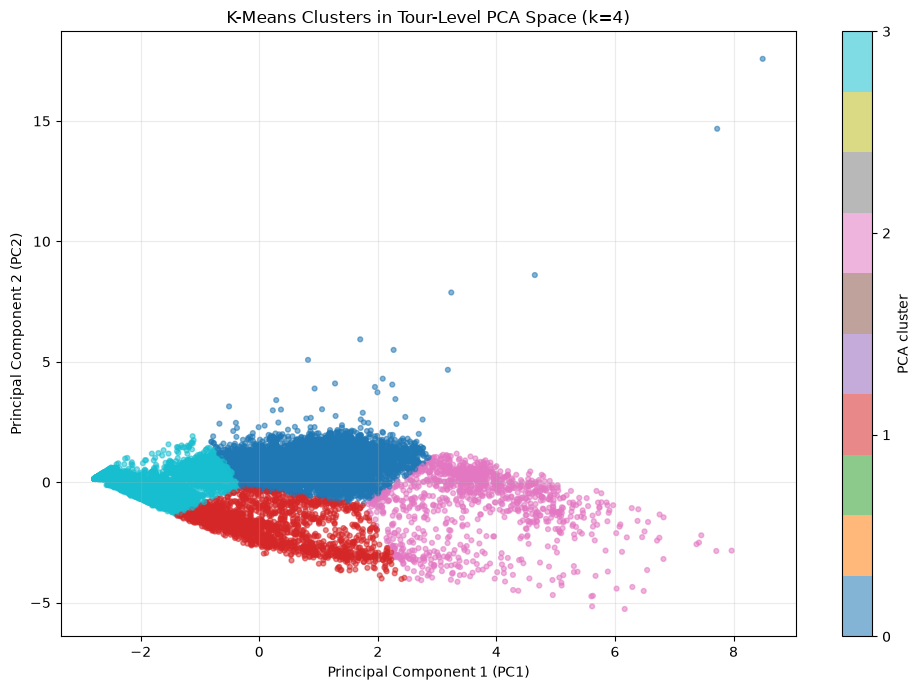

In [12]:
import matplotlib.pyplot as plt

plot_data = final_tour_clusters[
    ["PC1", "PC2", "pca_cluster"]
].dropna()

fig, ax = plt.subplots(figsize=(10, 7))

scatter = ax.scatter(
    plot_data["PC1"],
    plot_data["PC2"],
    c=plot_data["pca_cluster"],
    cmap="tab10",
    s=12,
    alpha=0.55
)

ax.set_title("K-Means Clusters in Tour-Level PCA Space (k=4)")
ax.set_xlabel("Principal Component 1 (PC1)")
ax.set_ylabel("Principal Component 2 (PC2)")
ax.grid(True, alpha=0.25)

colorbar = fig.colorbar(scatter, ax=ax, ticks=[0, 1, 2, 3])
colorbar.set_label("PCA cluster")

plt.tight_layout()
plt.show()

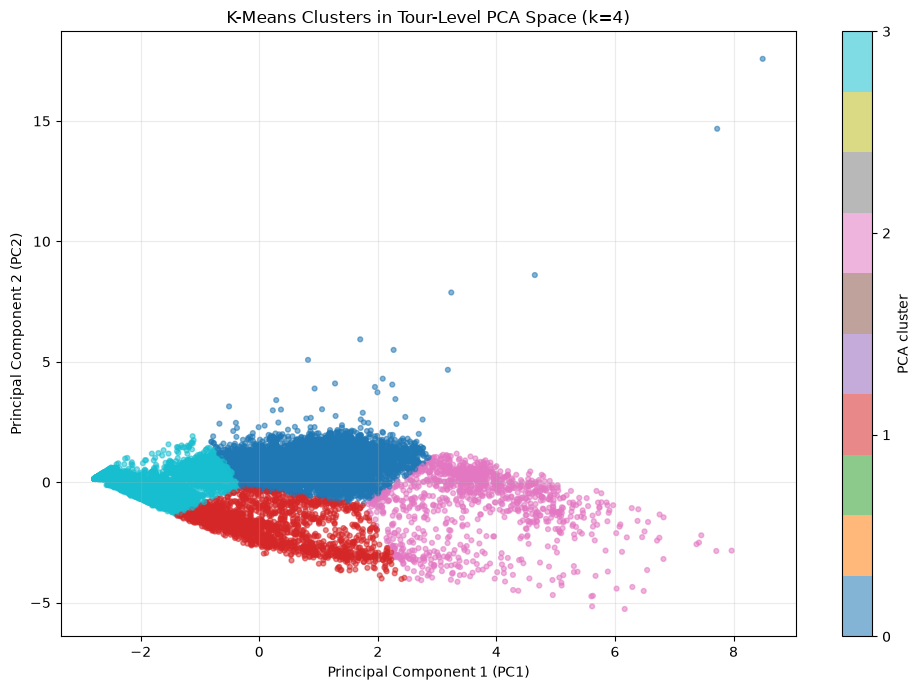

Figure saved: /Users/divyshah/Downloads/dt-cargo-vehicle-telemetry--main/data/processed/tour_level_pca/tour_level_pca_kmeans_k4_scatter.png


In [13]:
figure_path = OUTPUT_DIR / "tour_level_pca_kmeans_k4_scatter.png"

fig, ax = plt.subplots(figsize=(10, 7))

scatter = ax.scatter(
    plot_data["PC1"],
    plot_data["PC2"],
    c=plot_data["pca_cluster"],
    cmap="tab10",
    s=12,
    alpha=0.55
)

ax.set_title("K-Means Clusters in Tour-Level PCA Space (k=4)")
ax.set_xlabel("Principal Component 1 (PC1)")
ax.set_ylabel("Principal Component 2 (PC2)")
ax.grid(True, alpha=0.25)

colorbar = fig.colorbar(scatter, ax=ax, ticks=[0, 1, 2, 3])
colorbar.set_label("PCA cluster")

plt.tight_layout()
fig.savefig(figure_path, dpi=200, bbox_inches="tight")
plt.show()

print("Figure saved:", figure_path)

## 11. Comparing Operational Cluster Profiles

This analysis compares the median original operational features across the four PCA-based clusters. The features are standardized for visualization only, allowing distance, duration, speed, and track count to be compared on a common scale.

The underlying cluster assignments and original measurements remain unchanged. Median profiles are used because the tour-level variables are skewed and contain extreme observations.

The resulting figure helps distinguish the operational characteristics of each group without treating PCA component values as directly interpretable physical measurements.

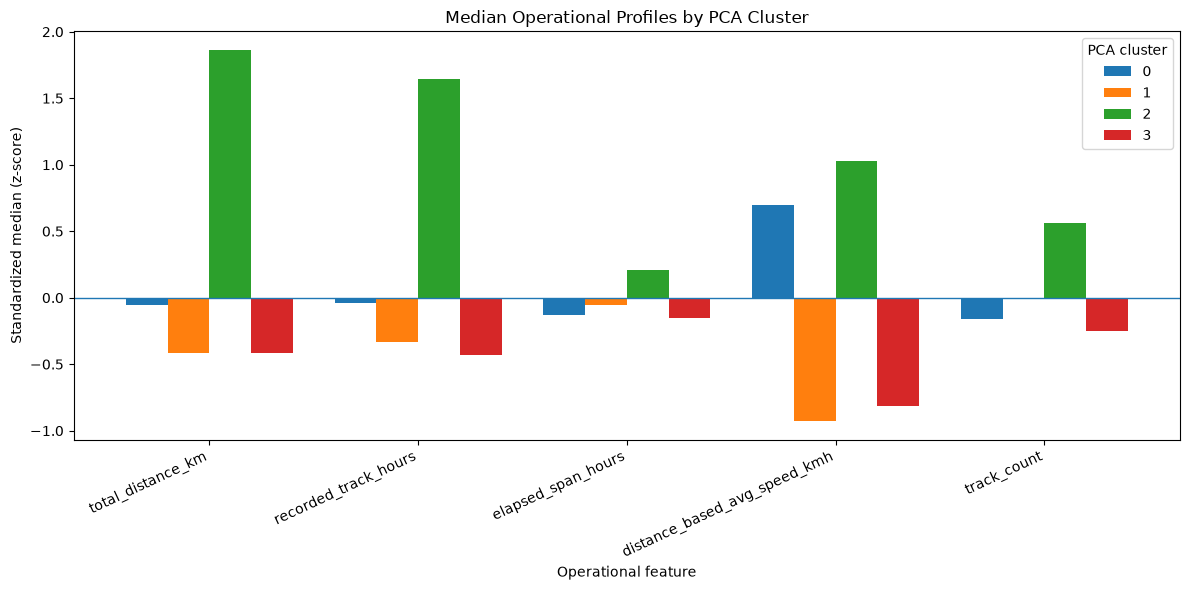

In [14]:
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import pandas as pd

profile_columns = [
    "total_distance_km",
    "recorded_track_hours",
    "elapsed_span_hours",
    "distance_based_avg_speed_kmh",
    "track_count",
]

# Median values in original units.
cluster_medians = (
    final_tour_clusters
    .groupby("pca_cluster")[profile_columns]
    .median()
)

# Standardize the cluster medians for visual comparison only.
# Fit the scaler to all individual tours, then transform the medians.
profile_scaler = StandardScaler()
profile_scaler.fit(final_tour_clusters[profile_columns])

scaled_medians = pd.DataFrame(
    profile_scaler.transform(cluster_medians),
    index=cluster_medians.index,
    columns=profile_columns,
)

ax = scaled_medians.T.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8,
)

ax.set_title("Median Operational Profiles by PCA Cluster")
ax.set_xlabel("Operational feature")
ax.set_ylabel("Standardized median (z-score)")
ax.axhline(0, linewidth=1)
ax.legend(title="PCA cluster")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

## 12. Final Operational Summary of PCA Clusters

This section consolidates the four PCA-based K-Means clusters into a report-ready summary. Each cluster is described using its size, median operational measurements in original units, and quality-review rate.

Cluster descriptions remain provisional because the observations represent candidate tours constructed from telemetry records, not independently verified real-world trips. Quality flags are retained and reported rather than used as automatic exclusion criteria.

In [15]:
cluster_summary = (
    final_tour_clusters
    .groupby("pca_cluster")
    .agg(
        tour_count=("tour_id", "size"),
        median_distance_km=("total_distance_km", "median"),
        median_recorded_hours=("recorded_track_hours", "median"),
        median_elapsed_hours=("elapsed_span_hours", "median"),
        median_speed_kmh=("distance_based_avg_speed_kmh", "median"),
        median_track_count=("track_count", "median"),
        quality_review_count=("requires_quality_review", "sum"),
    )
)

cluster_summary["tour_percentage"] = (
    100 * cluster_summary["tour_count"] / len(final_tour_clusters)
).round(2)

cluster_summary["quality_review_percentage"] = (
    100 * cluster_summary["quality_review_count"]
    / cluster_summary["tour_count"]
).round(2)

display(cluster_summary.round(3))

summary_path = OUTPUT_DIR / "tour_level_pca_kmeans_k4_cluster_summary.csv"
cluster_summary.to_csv(summary_path)

print("Summary saved:", summary_path)

,tour_count,median_distance_km,median_recorded_hours,median_elapsed_hours,median_speed_kmh,median_track_count,quality_review_count,tour_percentage,quality_review_percentage
pca_cluster,,,,,,,,,
0,5390,117.560,3.230,5.065,40.828,5.0,69,40.18,1.28
1,2011,2.065,0.980,17.133,2.216,10.0,66,14.99,3.28
2,1100,739.768,16.067,58.914,48.567,28.0,87,8.20,7.91
3,4912,0.908,0.221,0.751,4.965,2.0,42,36.62,0.86


Summary saved: /Users/divyshah/Downloads/dt-cargo-vehicle-telemetry--main/data/processed/tour_level_pca/tour_level_pca_kmeans_k4_cluster_summary.csv


In [16]:
report_columns = [
    "tour_count",
    "tour_percentage",
    "median_distance_km",
    "median_recorded_hours",
    "median_elapsed_hours",
    "median_speed_kmh",
    "median_track_count",
    "quality_review_count",
    "quality_review_percentage",
]

display(
    cluster_summary[report_columns]
    .rename(columns={
        "tour_count": "Tours",
        "tour_percentage": "Tours (%)",
        "median_distance_km": "Median distance (km)",
        "median_recorded_hours": "Median recorded hours",
        "median_elapsed_hours": "Median elapsed hours",
        "median_speed_kmh": "Median speed (km/h)",
        "median_track_count": "Median track count",
        "quality_review_count": "Tours requiring review",
        "quality_review_percentage": "Review rate (%)",
    })
    .round(2)
)

,Tours,Tours (%),Median distance (km),Median recorded hours,Median elapsed hours,Median speed (km/h),Median track count,Tours requiring review,Review rate (%)
pca_cluster,,,,,,,,,
0,5390,40.18,117.56,3.23,5.06,40.83,5.0,69,1.28
1,2011,14.99,2.06,0.98,17.13,2.22,10.0,66,3.28
2,1100,8.20,739.77,16.07,58.91,48.57,28.0,87,7.91
3,4912,36.62,0.91,0.22,0.75,4.96,2.0,42,0.86


## 13. Conclusion

Tour-level PCA reduced five operational features to two principal components while retaining 91.081% of the standardized feature variance. K-Means clustering with four clusters produced four distinct descriptive profiles across 13,413 candidate tours.

The PCA-space solution achieved a sampled silhouette score of 0.4983 at \(k=4\), compared with 0.4525 for the five-dimensional standardized-feature solution. Agreement between the two partitions was high (ARI = 0.944), suggesting that PCA preserved most of the broad grouping structure. The cluster assignments were also highly consistent across random initializations.

The resulting groups differ in distance, recorded duration, elapsed span, speed, and track count. The long-distance, high-activity group has the highest median distance and a relatively high quality-review rate. Low-distance groups exhibit contrasting elapsed-span patterns, which may warrant further investigation of telemetry gaps and candidate-tour construction.

These clusters are exploratory profiles, not verified operational categories. Quality flags were retained, and the analysis does not establish causal explanations, fuel efficiency, or overall fleet performance. Further validation using domain knowledge, temporal patterns, and independent operational evidence is required before using the clusters for operational decisions.